In [1]:
from comptest.image_transform import DataTransform
from comptest.configurations import (
    TIFFFILE_JPEGXL_LOSSY_CONFIGS,
    TIFFFILE_JPEGXL_LOSSY_CONFIGS_EFFORT_7_BIG,
)
from comptest.constants import DATASETS_RECONSTRUCTIONS_DIR
import shutil
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

%load_ext autoreload
%autoreload 2

In [2]:
DATASET = "Canislupus_CZM_712"
# DATASET_DIR = DATASETS_DIR / DATASET
DATASET_DIR = DATASETS_RECONSTRUCTIONS_DIR / "CIL_basic_binned_2x2" / DATASET
assert DATASET_DIR.is_dir()

INPUT_FILES = sorted(
    [
        *DATASET_DIR.glob("*.tif"),
        *DATASET_DIR.glob("*.tiff"),
    ]
)


In [3]:
from pathlib import Path

OUTPUT_DIR = Path("output")
assert OUTPUT_DIR.is_dir()

OUTPUT_QUALITY_DIR = OUTPUT_DIR / "quality_viewer"
OUTPUT_QUALITY_DIR.mkdir(exist_ok=True, parents=True)

OUT_DIR = OUTPUT_QUALITY_DIR / DATASET
OUT_DIR.mkdir(exist_ok=True, parents=True)

OUT_DIR_TIFFS = OUT_DIR / "tiffs"
OUT_DIR_TIFFS.mkdir(exist_ok=True, parents=True)


In [4]:
input_file = INPUT_FILES[len(INPUT_FILES) // 2]


In [5]:
# Copy over original
original_img_path = OUT_DIR_TIFFS / f"{input_file.stem}_original.original.tiff"
shutil.copy(input_file, original_img_path)
compressor_kwargs = {"n_jobs": None}

original_img = Image.open(OUT_DIR_TIFFS / f"{input_file.stem}_original.original.tiff")
original_img_arr = np.array(original_img)


# NOTE: We need to transform first, even lossy mode is broken for JXL f32
# TODO: Report to libjxl/imagecodecs
transform = DataTransform.infer(original_img_arr, target_range=(0, 1.0))


def _transform_image(img_path: Path, out_path: Path):
    img = Image.open(img_path)
    img_arr = np.array(img)
    img_arr = transform.apply(img_arr)
    transformed_img = Image.fromarray(img_arr)
    transformed_img.save(out_path)


_transform_image(
    original_img_path, OUT_DIR_TIFFS / f"{input_file.stem}_original.decompressed.tiff"
)

for cfg in TIFFFILE_JPEGXL_LOSSY_CONFIGS_EFFORT_7_BIG:
    # if cfg.effort != 7:
    #     continue

    compressed_output_file = OUT_DIR_TIFFS / f"{input_file.stem}_{cfg.name}.tiff"
    shutil.copy(input_file, compressed_output_file.with_suffix(".original.tiff"))

    # Transform input file
    transformed_input_file = (
        OUT_DIR_TIFFS / f"{input_file.stem}_{cfg.name}.transformed.tiff"
    )
    _transform_image(input_file, transformed_input_file)

    cfg.compressor[0](
        [transformed_input_file],
        [compressed_output_file],
        *cfg.compressor[1],
        **cfg.compressor[2] | compressor_kwargs,
    )
    cfg.decompressor[0](
        [compressed_output_file],
        [compressed_output_file.with_suffix(".decompressed.tiff")],
        *cfg.decompressor[1],
        **cfg.decompressor[2] | compressor_kwargs,
    )


/tmp/ipykernel_559837/4123068606.py:15: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))


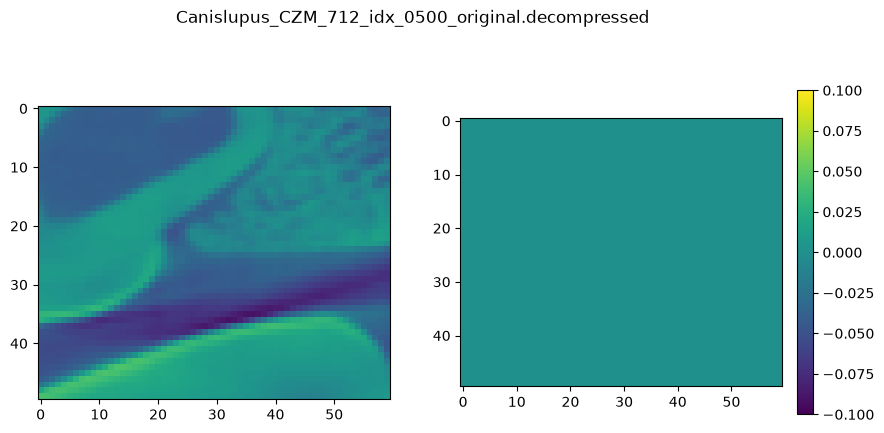

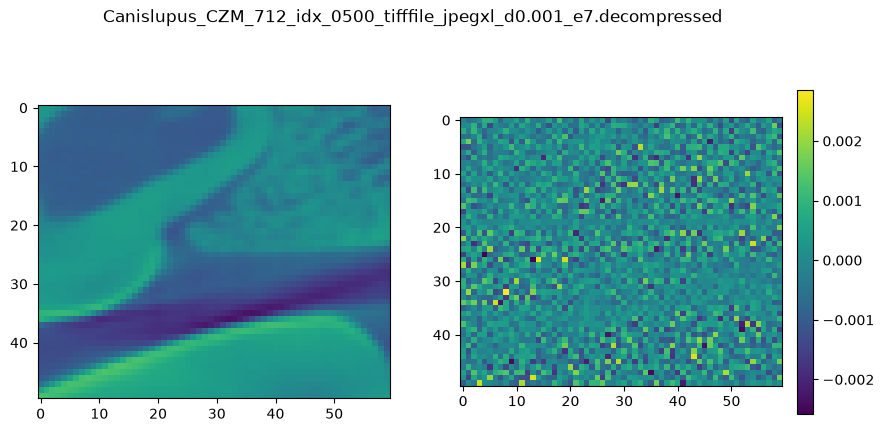

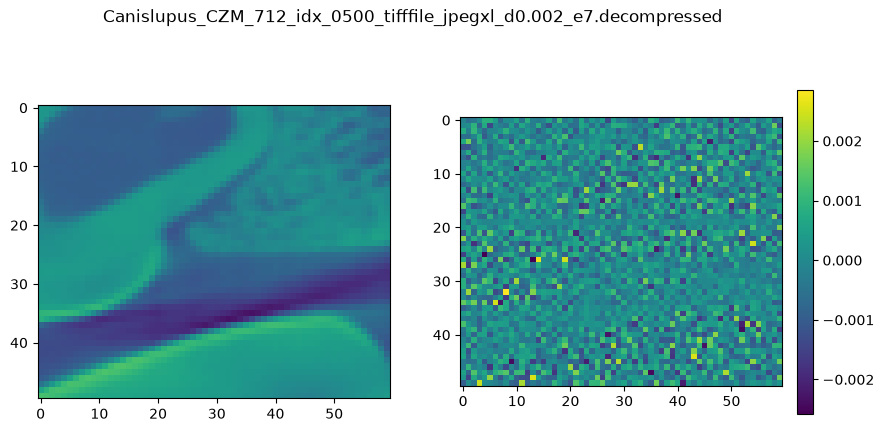

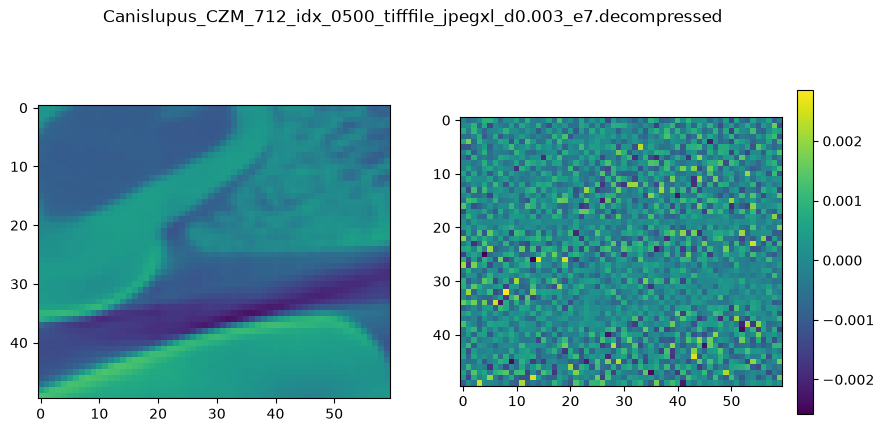

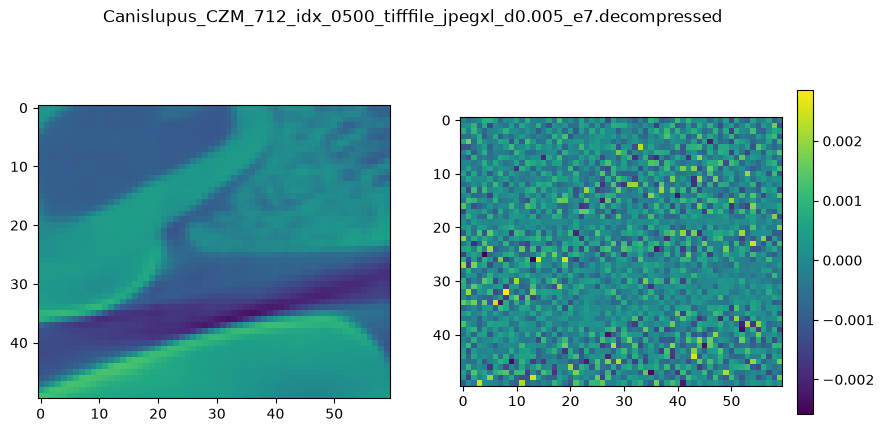

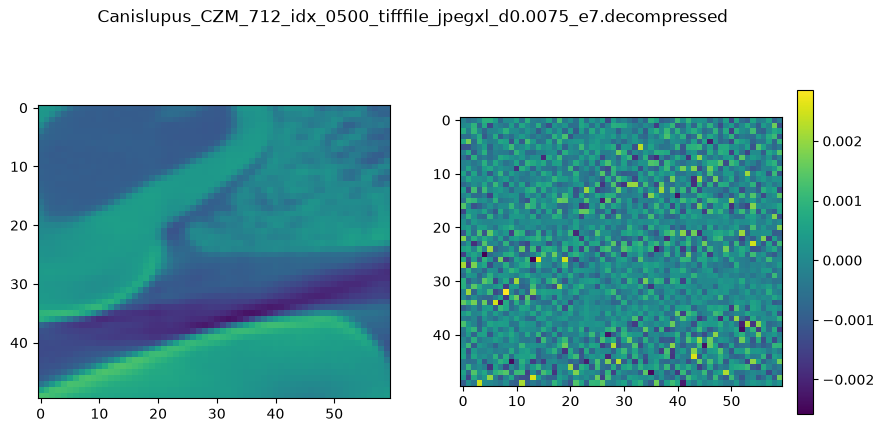

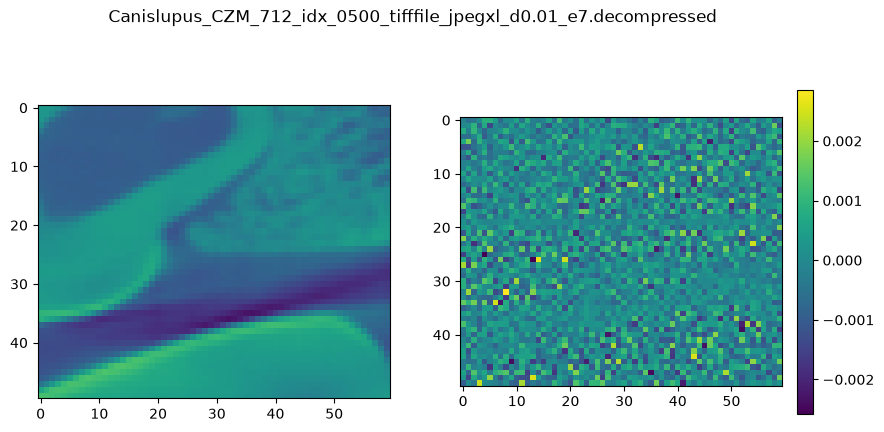

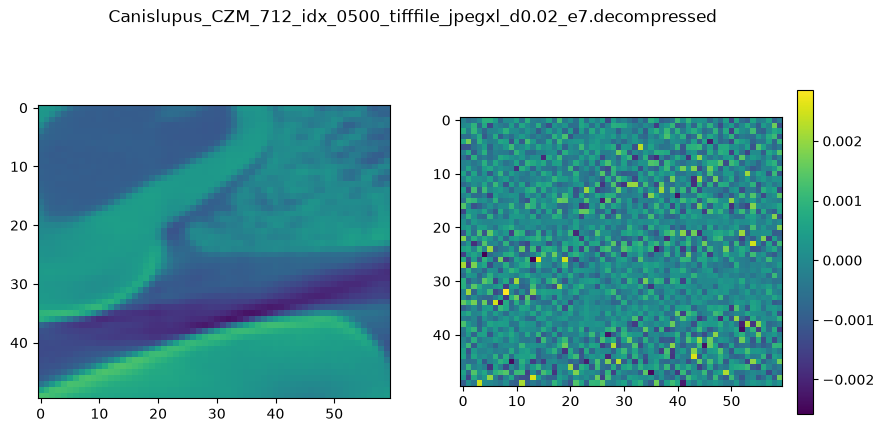

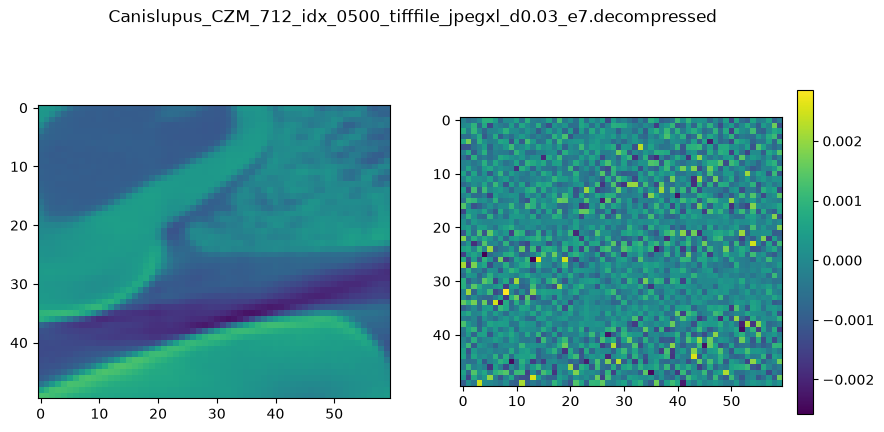

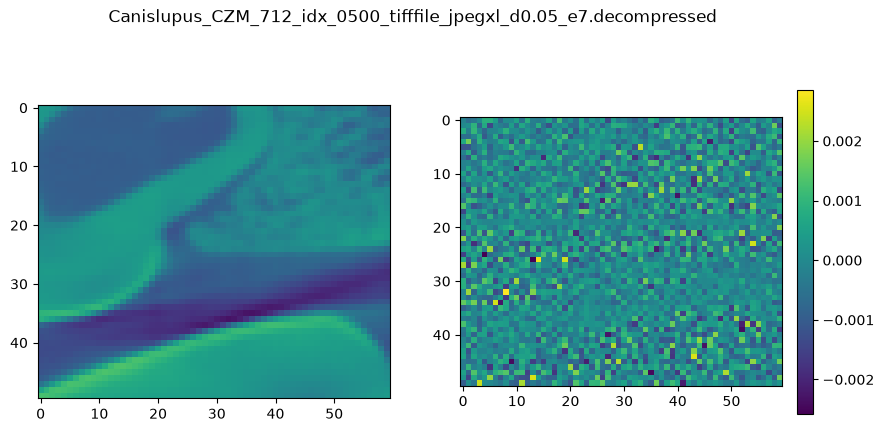

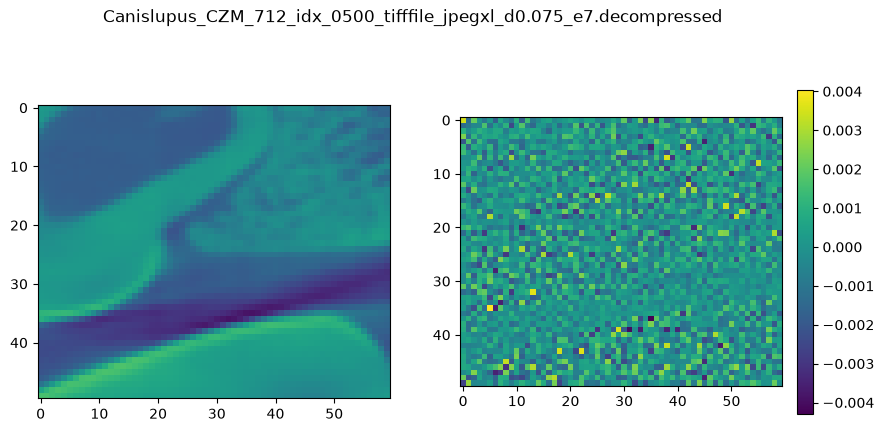

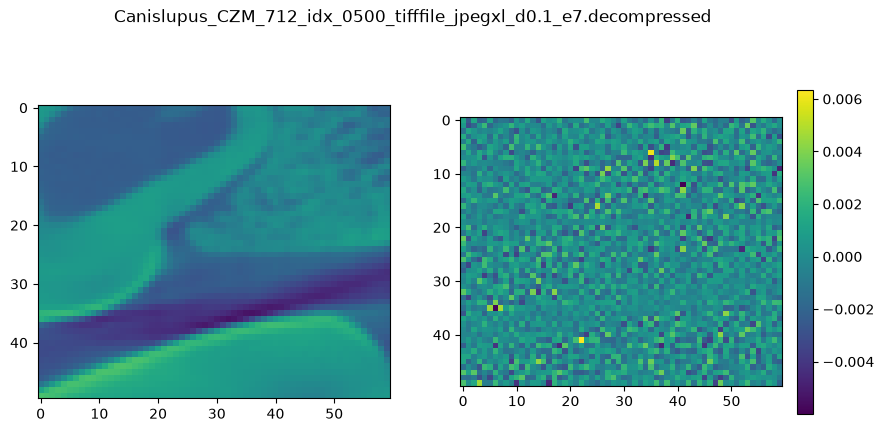

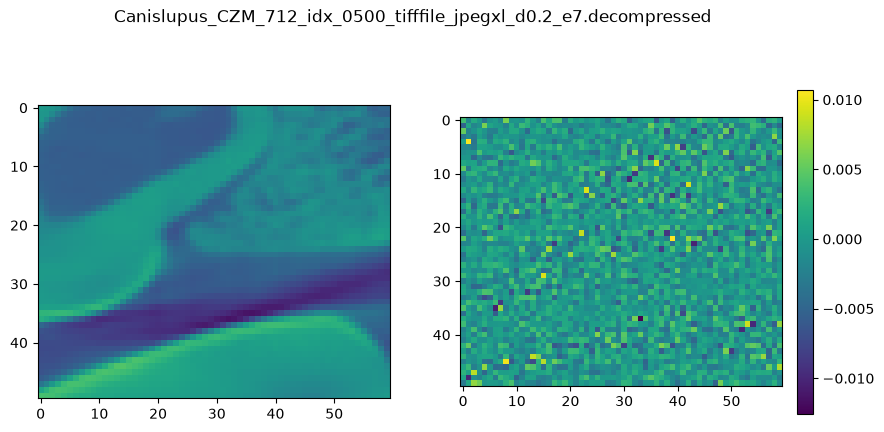

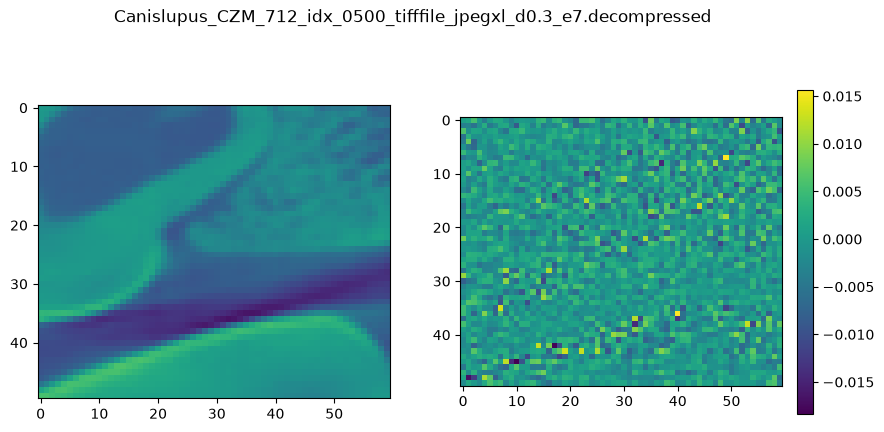

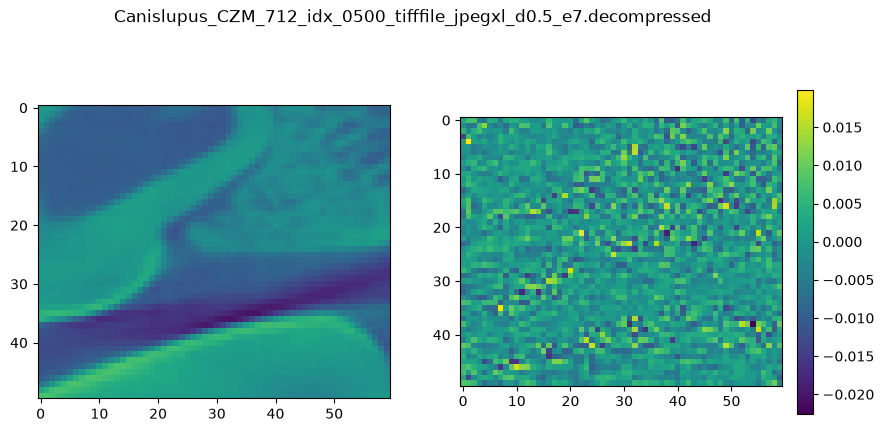

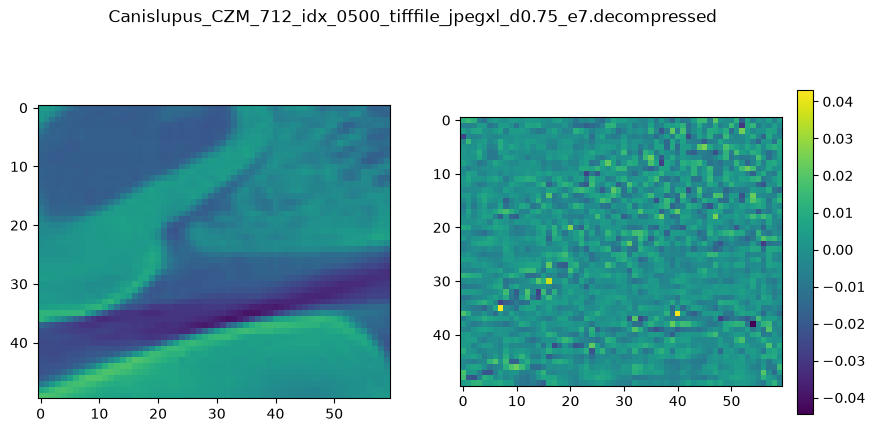

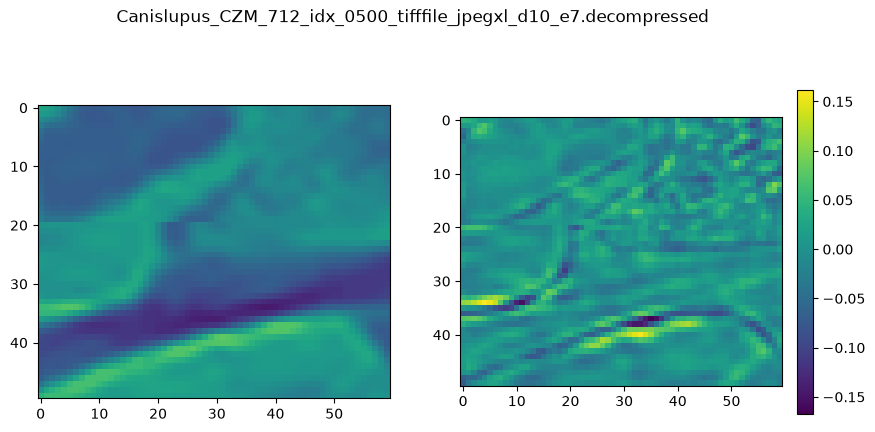

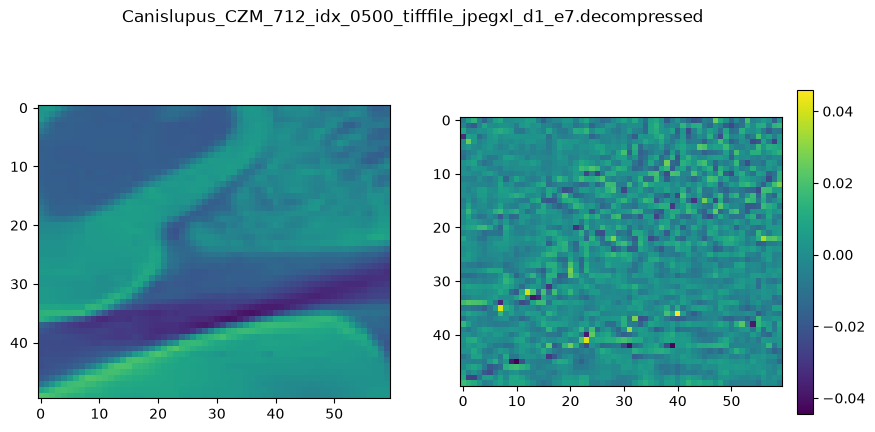

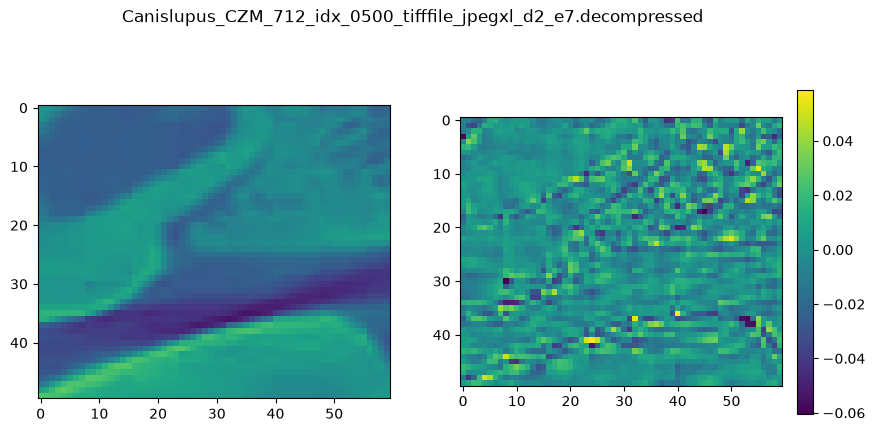

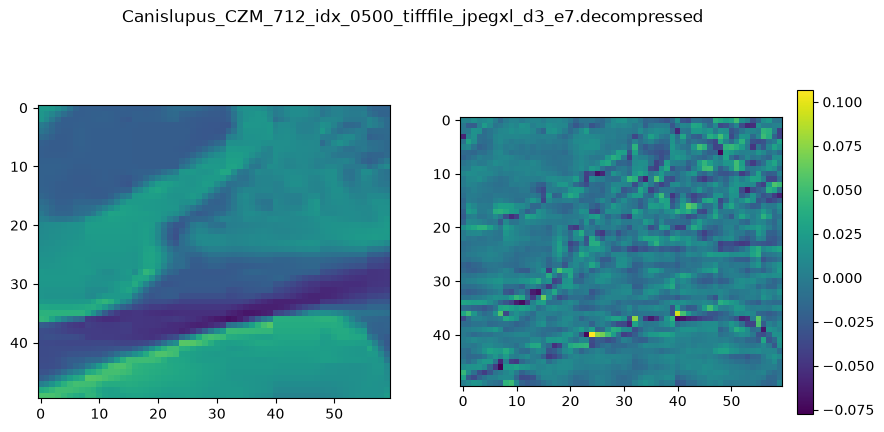

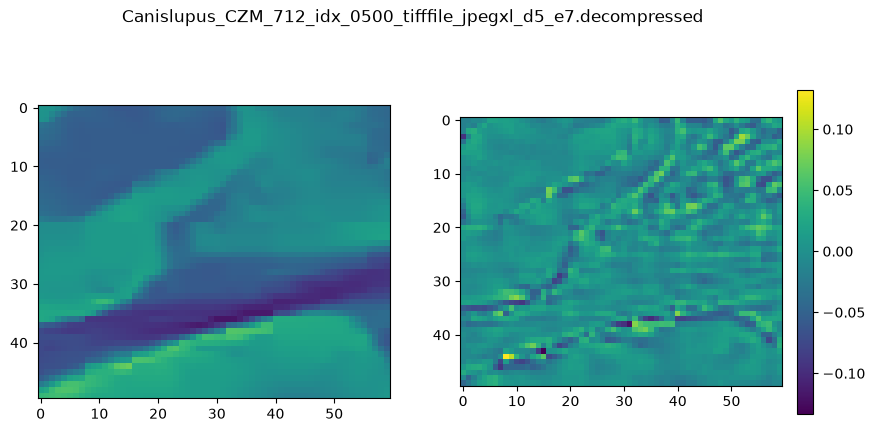

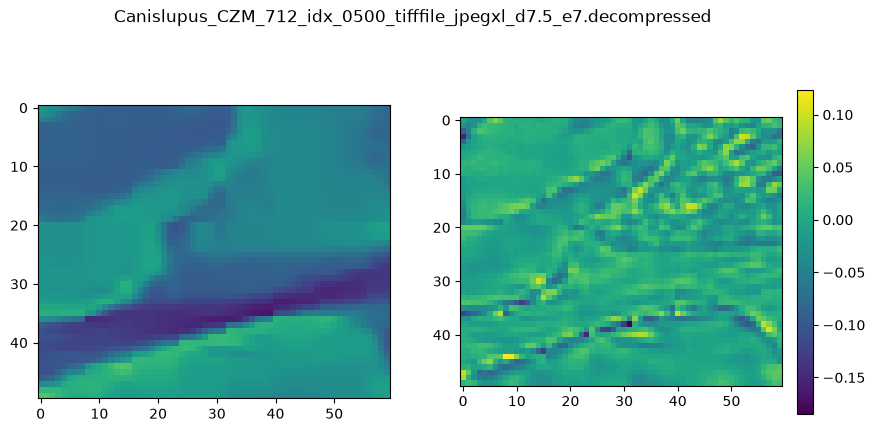

In [6]:
CROP_AREA = (560, 630, 560 + 60, 630 + 50)  # (left, upper, right, lower)
original_img = Image.open(
    OUT_DIR_TIFFS / f"{input_file.stem}_original.decompressed.tiff"
)
original_img_arr = np.array(original_img)
# transform = DataTransform.infer(original_img_arr, target_range=(0, 1.0))
# original_img_arr = transform.apply(original_img_arr)

original_img_cropped = Image.fromarray(original_img_arr).crop(CROP_AREA)
original_img_arr_cropped = np.array(original_img_cropped)
for file in sorted(OUT_DIR_TIFFS.glob("*decompressed.tiff")):
    img = Image.open(file)
    img = img.crop(CROP_AREA)
    img_arr = np.array(img)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(img_arr, vmin=0, vmax=1.0)
    ax2.imshow(img_arr - original_img_arr_cropped)
    plt.colorbar(ax2.images[0], ax=ax2, fraction=0.046, pad=0.04)
    fig.suptitle(file.stem)


In [7]:
(img_arr - original_img_arr_cropped).max()

np.float32(0.12382996)